# ML LAB 7

# Name : Kashif Khan

# Roll no : 35


# Batch - C3


In [ ]:
# GAUSSIAN CLASS,MULTINOMIAL , BERNOULLI CLASS

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder ,StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score as f1_score_func,classification_report,confusion_matrix)

pd.set_option('display.max_columns',None)

In [ ]:
df = pd.read_excel("Raisin_Dataset.xlsx")

In [ ]:
df.head()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
0,87524,442.246011,253.291155,0.819738,90546,0.758651,1184.040,Kecimen
1,75166,406.690687,243.032436,0.801805,78789,0.684130,1121.786,Kecimen
2,90856,442.267048,266.328318,0.798354,93717,0.637613,1208.575,Kecimen
3,45928,286.540559,208.760042,0.684989,47336,0.699599,844.162,Kecimen
4,79408,352.190770,290.827533,0.564011,81463,0.792772,1073.251,Kecimen


In [ ]:
df.tail()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
895,83248,430.077308,247.838695,0.817263,85839,0.668793,1129.072,Besni
896,87350,440.735698,259.293149,0.808629,90899,0.636476,1214.252,Besni
897,99657,431.706981,298.837323,0.721684,106264,0.741099,1292.828,Besni
898,93523,476.344094,254.176054,0.845739,97653,0.658798,1258.548,Besni
899,85609,512.081774,215.271976,0.907345,89197,0.632020,1272.862,Besni


In [ ]:
df.shape

(900, 8)

In [ ]:
df.describe()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter
count,900.000000,900.000000,900.000000,900.000000,900.000000,900.000000,900.000000
mean,87804.127778,430.929950,254.488133,0.781542,91186.090000,0.699508,1165.906636
std,39002.111390,116.035121,49.988902,0.090318,40769.290132,0.053468,273.764315
min,25387.000000,225.629541,143.710872,0.348730,26139.000000,0.379856,619.074000
25%,59348.000000,345.442898,219.111126,0.741766,61513.250000,0.670869,966.410750
50%,78902.000000,407.803951,247.848409,0.798846,81651.000000,0.707367,1119.509000
75%,105028.250000,494.187014,279.888575,0.842571,108375.750000,0.734991,1308.389750
max,235047.000000,997.291941,492.275279,0.962124,278217.000000,0.835455,2697.753000


In [ ]:
df.dtypes

,0
Area,int64
MajorAxisLength,float64
MinorAxisLength,float64
Eccentricity,float64
ConvexArea,int64
Extent,float64
Perimeter,float64
Class,object


In [ ]:
df.isnull().sum()

,0
Area,0
MajorAxisLength,0
MinorAxisLength,0
Eccentricity,0
ConvexArea,0
Extent,0
Perimeter,0
Class,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             900 non-null    int64  
 1   MajorAxisLength  900 non-null    float64
 2   MinorAxisLength  900 non-null    float64
 3   Eccentricity     900 non-null    float64
 4   ConvexArea       900 non-null    int64  
 5   Extent           900 non-null    float64
 6   Perimeter        900 non-null    float64
 7   Class            900 non-null    object 
dtypes: float64(5), int64(2), object(1)
memory usage: 56.4+ KB


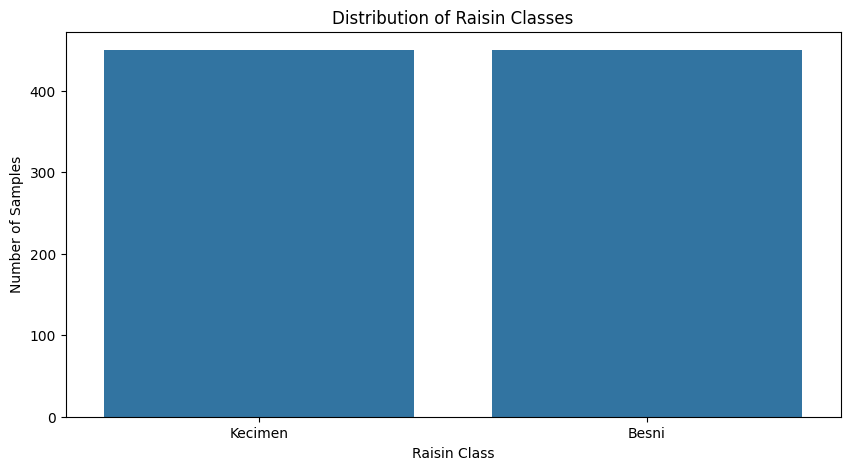

In [ ]:
plt.figure(figsize=(10,5))
sns.countplot(data=df,x='Class')
plt.title("Distribution of Raisin Classes")
plt.xlabel("Raisin Class")
plt.ylabel("Number of Samples")
plt.show()

In [ ]:
# pie chart

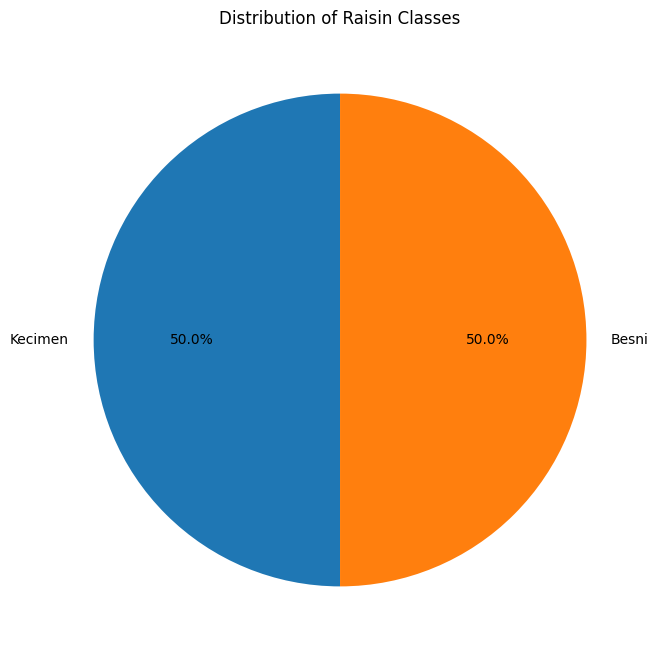

In [ ]:
class_counts = df["Class"].value_counts()
plt.figure(figsize=(8,8))
plt.pie(class_counts,labels=class_counts.index,autopct="%1.1f%%",startangle=90)
plt.title("Distribution of Raisin Classes")
plt.show()

In [ ]:
numerical_features = df.select_dtypes(include=np.number).columns
print("numerical features:")
print(numerical_features.tolist())

numerical features:
['Area', 'MajorAxisLength', 'MinorAxisLength', 'Eccentricity', 'ConvexArea', 'Extent', 'Perimeter']


In [ ]:
#histograms

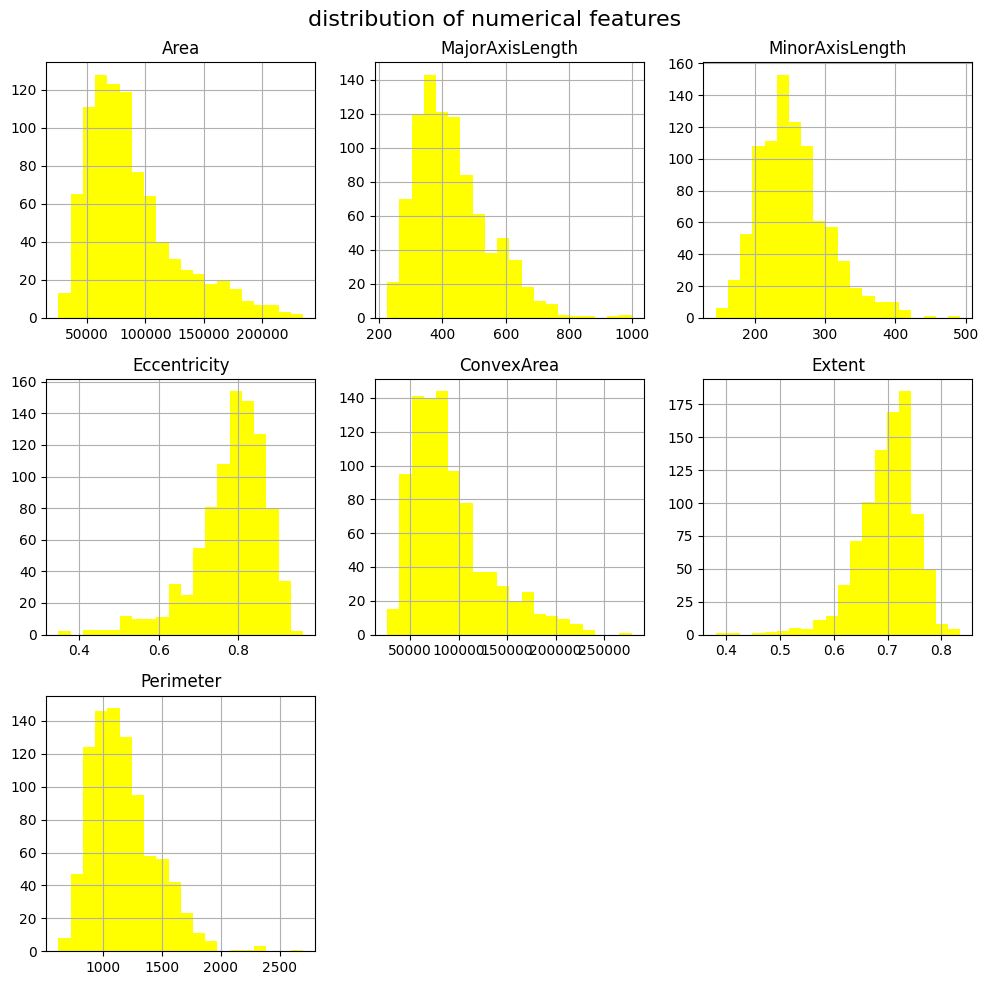

In [ ]:
df[numerical_features].hist(figsize=(10,10),bins = 20,color='yellow')
plt.suptitle("distribution of numerical features",fontsize=16)
plt.tight_layout()
plt.show()

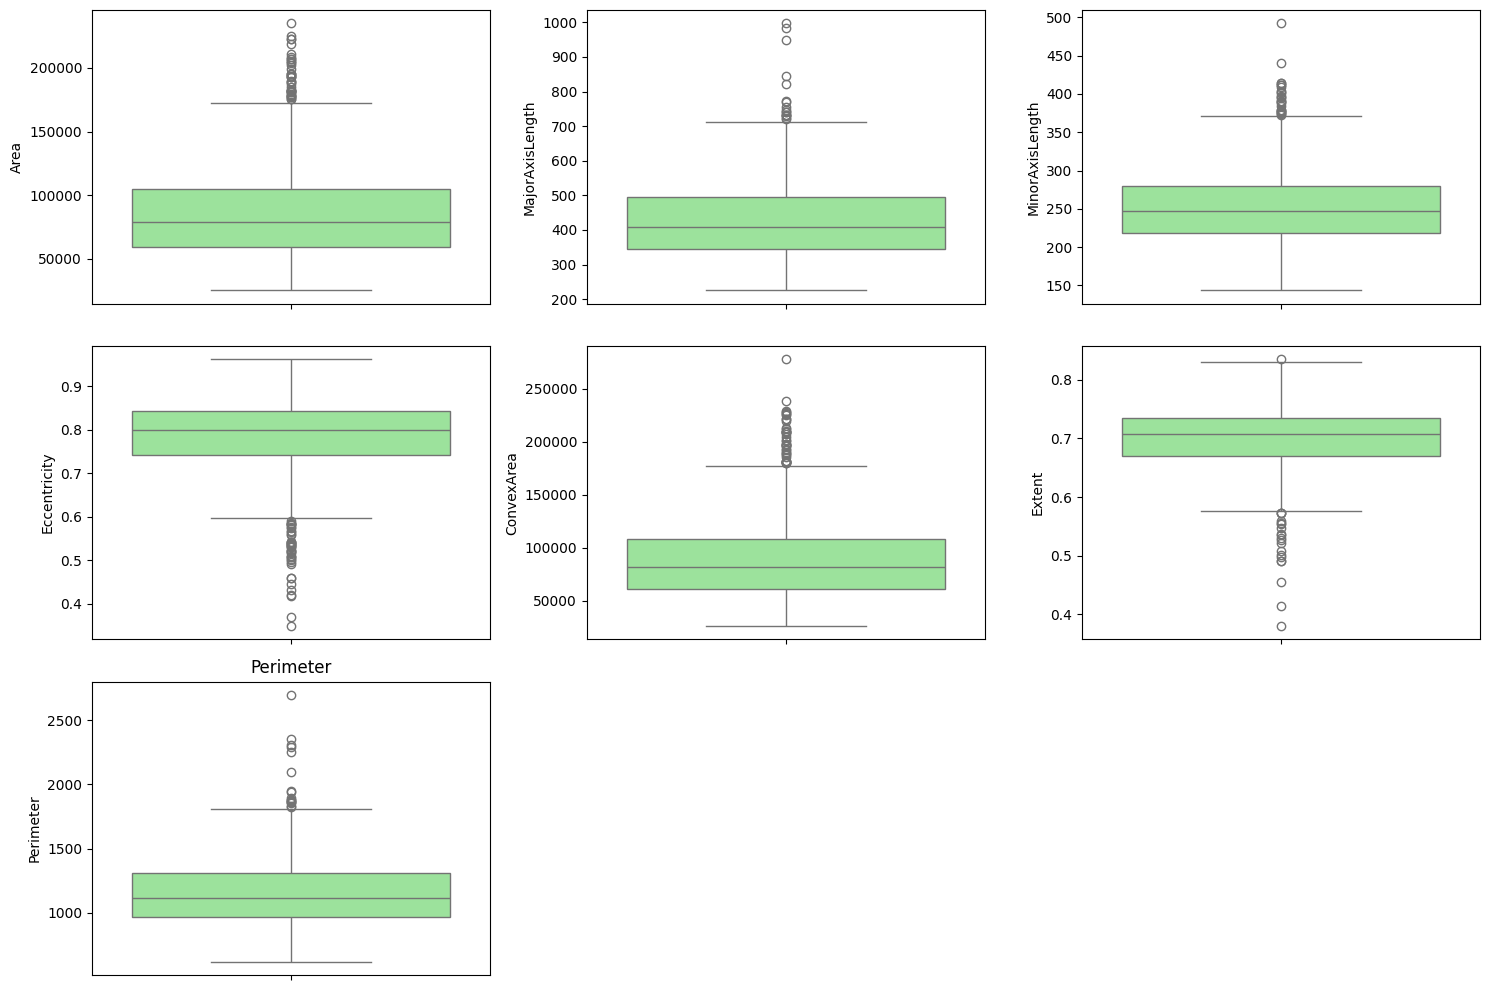

In [ ]:
plt.figure(figsize=(15,10))
for i , column in enumerate(numerical_features,1):
    plt.subplot(3,3,i)
    sns.boxplot(y = df[column],color = 'lightgreen' )
plt.title(column)
plt.tight_layout()
plt.show()

In [ ]:
# histograms with kde function

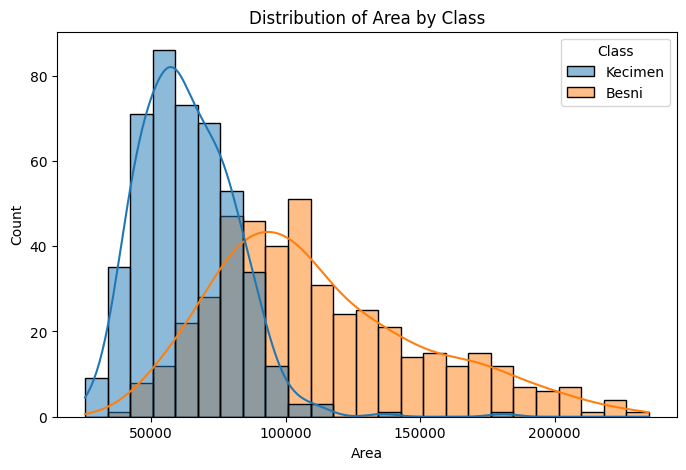

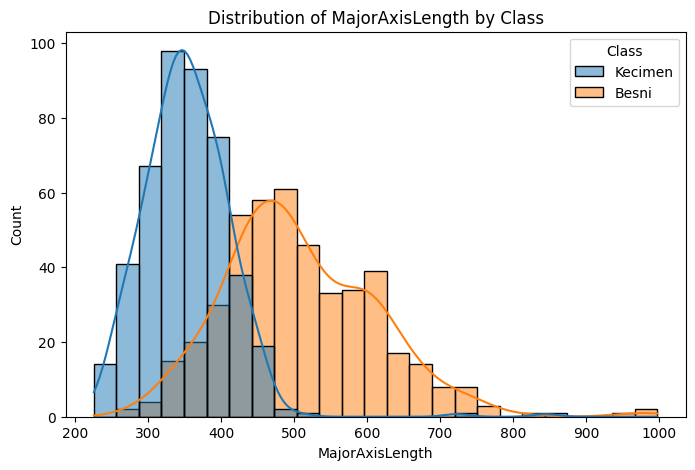

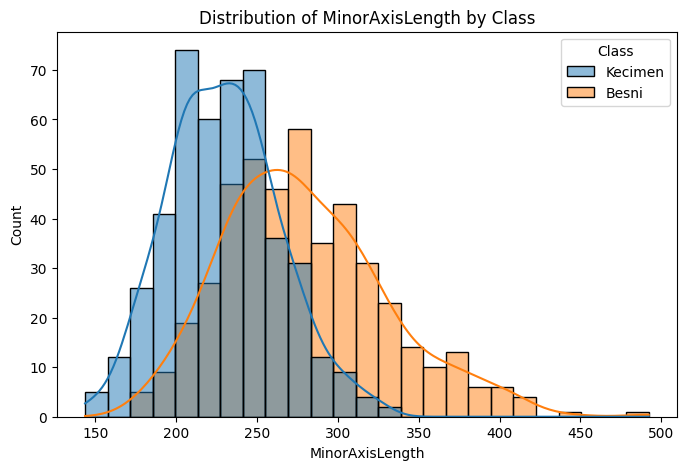

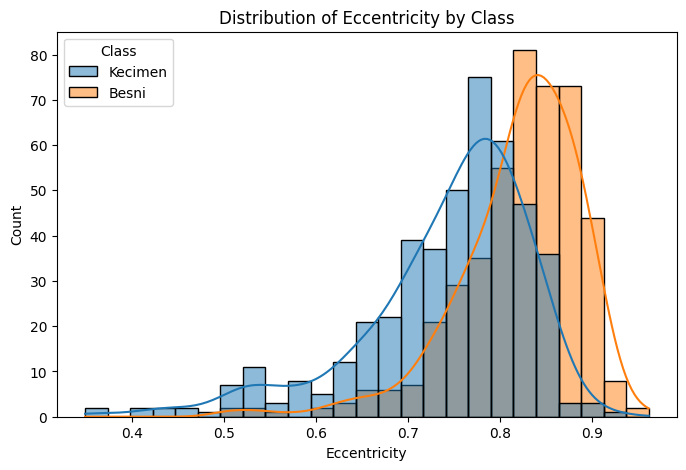

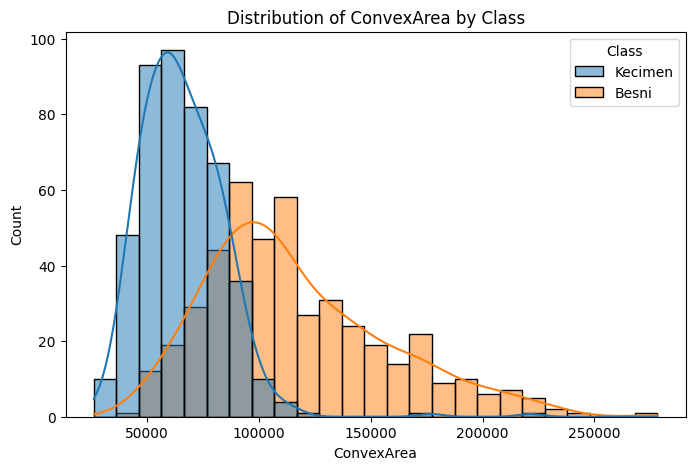

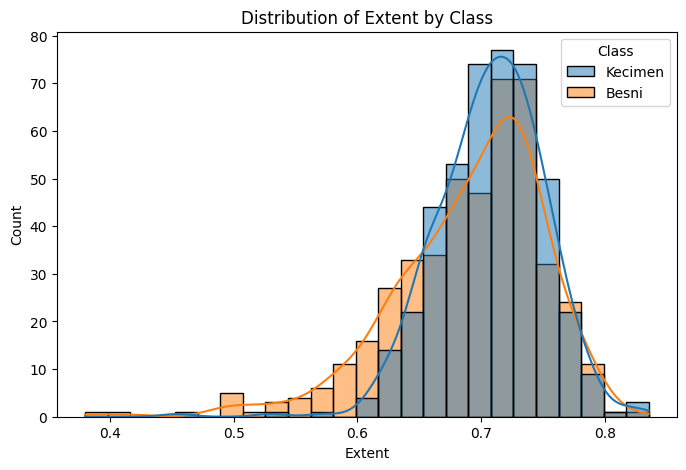

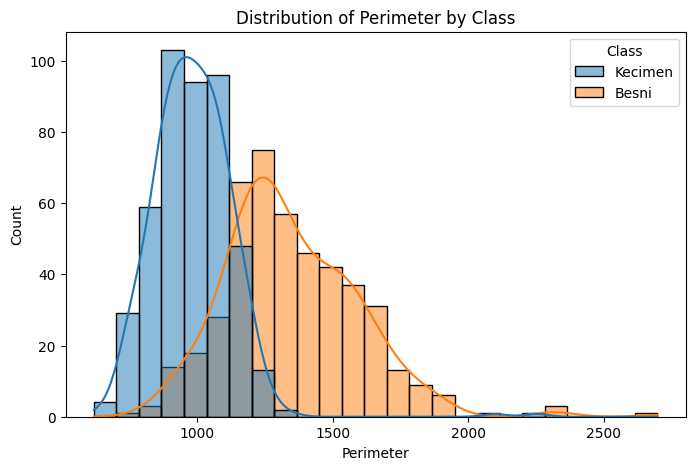

In [ ]:
for column in numerical_features:
  plt.figure(figsize=(8,5))
  sns.histplot(data=df,x = column,hue="Class",kde=True,bins=25)
  plt.title(f"Distribution of {column} by Class")
  plt.xlabel(column)
  plt

In [ ]:
# corelation Matrix

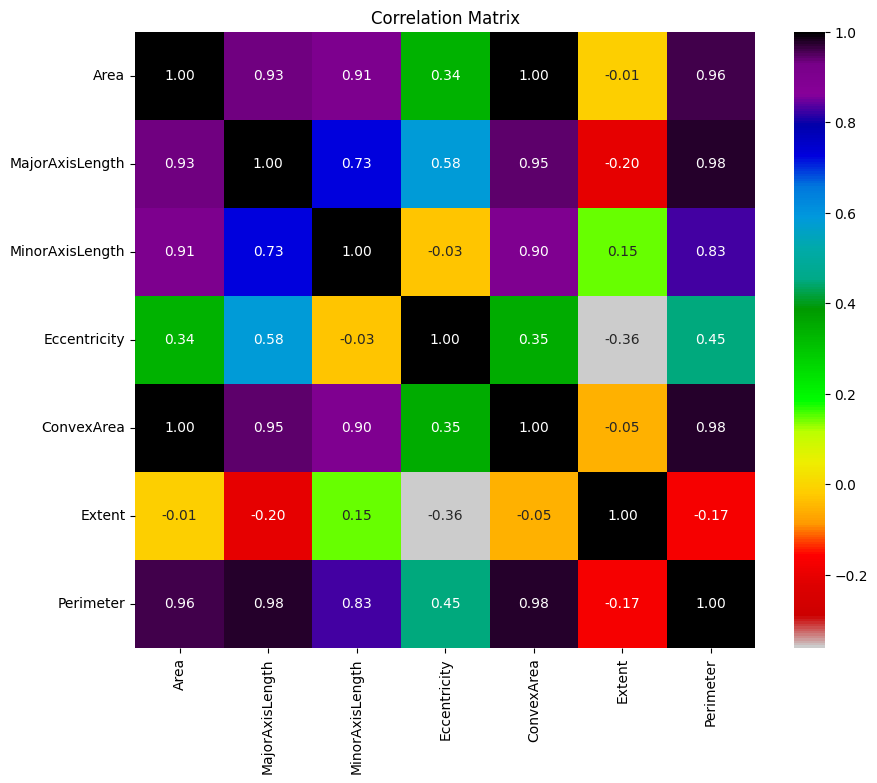

In [ ]:
correlation_matrix = df[numerical_features].corr()
plt.figure(figsize=(10,8))
sns.heatmap(correlation_matrix,annot=True,cmap='nipy_spectral_r',fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

In [ ]:
# scatter plot

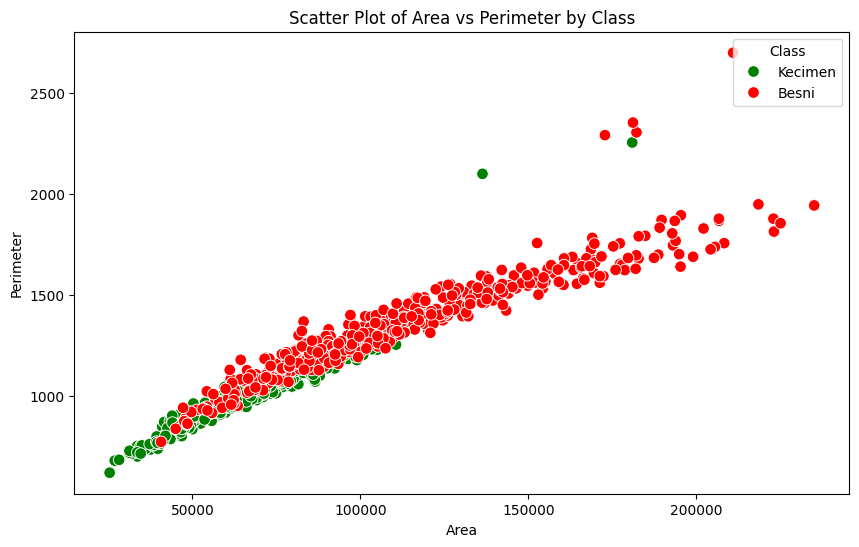

In [ ]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=df,x='Area',y='Perimeter',hue='Class',s=70,palette={'Kecimen':'green','Besni':'red'})
plt.title("Scatter Plot of Area vs Perimeter by Class")
plt.xlabel("Area")
plt.ylabel("Perimeter")
plt.show()

In [ ]:
label_encoder = LabelEncoder()
df["Class_encoded"] = label_encoder.fit_transform(df["Class"])
print(df[["Class","Class_encoded"]].head(10))

     Class  Class_encoded
0  Kecimen              1
1  Kecimen              1
2  Kecimen              1
3  Kecimen              1
4  Kecimen              1
5  Kecimen              1
6  Kecimen              1
7  Kecimen              1
8  Kecimen              1
9  Kecimen              1


In [ ]:
X= df[numerical_features]
y = df["Class_encoded"]
print("shape of X:",X.shape)
print("shape of y:",y.shape)

shape of X: (900, 7)
shape of y: (900,)


In [ ]:
X = df[numerical_features]
y = df["Class_encoded"]
print("Ensuring X and y are correctly defined before train_test_split:")
print("shape of X:",X.shape)
print("shape of y:",y.shape)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42,stratify=y)

print("Training Sample:", X_train.shape[0])
print("Testing Sample:", X_test.shape[0])

Ensuring X and y are correctly defined before train_test_split:
shape of X: (900, 7)
shape of y: (900,)
Training Sample: 720
Testing Sample: 180


In [ ]:
gnb = GaussianNB()

In [ ]:
gnb = GaussianNB()
gnb.fit(X_train,y_train)

GaussianNB()

In [ ]:
y_pred = gnb.predict(X_test)
print("Predicted labels:")
print(y_pred)

Predicted labels:
[1 0 0 1 0 1 0 1 1 1 1 1 1 1 0 1 1 1 0 0 0 1 1 1 1 1 1 1 1 1 1 1 0 0 1 0 1
 0 0 0 0 0 0 0 0 0 0 1 0 0 1 1 0 1 1 1 0 1 0 0 0 1 1 0 0 1 0 1 1 1 1 0 0 1
 1 1 0 1 0 1 0 1 1 1 1 0 1 1 1 1 0 1 1 0 1 1 1 1 1 0 1 1 1 0 1 0 1 0 1 1 0
 1 1 0 1 1 1 0 0 1 0 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 0 1 1 1 0 1 1 0 0 1
 1 1 1 0 0 1 1 1 0 1 1 0 1 1 0 0 0 1 1 1 1 1 1 0 1 1 1 0 0 1 0 1]


In [ ]:
comparison = pd.DataFrame({'Actual': y_test.values, 'Predicted': y_pred})
print(comparison)

     Actual  Predicted
0         0          1
1         0          0
2         0          0
3         1          1
4         0          0
..      ...        ...
175       0          0
176       0          0
177       0          1
178       0          0
179       1          1

[180 rows x 2 columns]


In [ ]:
comparison["Actual_Class"] = label_encoder.inverse_transform(comparison["Actual"])
comparison["Predicted_Class"] = label_encoder.inverse_transform(comparison["Predicted"])
comparison.head(20)

,Actual,Predicted,Actual_Class,Predicted_Class
0,0,1,Besni,Kecimen
1,0,0,Besni,Besni
2,0,0,Besni,Besni
3,1,1,Kecimen,Kecimen
4,0,0,Besni,Besni
5,1,1,Kecimen,Kecimen
6,0,0,Besni,Besni
7,1,1,Kecimen,Kecimen
8,1,1,Kecimen,Kecimen
9,1,1,Kecimen,Kecimen


In [ ]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)
print("Accuracy(%)", accuracy*100)

Accuracy: 0.8166666666666667
Accuracy(%) 81.66666666666667


In [ ]:
precision = precision_score(y_test, y_pred)
print("Precision:", precision)

Precision: 0.7522123893805309


In [ ]:
recall = recall_score(y_test, y_pred)
print("Recall:", recall)

Recall: 0.9444444444444444


In [ ]:
f1_score_val_cd2 = f1_score_func(y_test, y_pred)
print("F1 Score:", f1_score_val_cd2)

F1 Score: 0.8374384236453202


In [ ]:
f1_score_val_ny = f1_score_func(y_test, y_pred)
print("F1 Score:", f1_score_val_ny)

F1 Score: 0.8374384236453202


In [ ]:
class_report = classification_report(y_test, y_pred, target_names=label_encoder.classes_)
print('Classification Report:\n', class_report)

Classification Report:
               precision    recall  f1-score   support

       Besni       0.93      0.69      0.79        90
     Kecimen       0.75      0.94      0.84        90

    accuracy                           0.82       180
   macro avg       0.84      0.82      0.81       180
weighted avg       0.84      0.82      0.81       180



In [ ]:
from sklearn.metrics import accuracy_score
y_train_pred = gnb.predict(X_train)
y_test_pred = gnb.predict(X_test)
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)
print("Training Accuracy:", train_accuracy)
print("testing Accuracy:", test_accuracy)

Training Accuracy: 0.8263888888888888
testing Accuracy: 0.8166666666666667
